# Taller Final – Segmentación de Clientes con K-Means
**Materia:** Inteligencia de Negocios y Minería de Datos
**Dataset:** Mall Customers (Kaggle)

## Parte 1 – Exploración de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib

sns.set_style("whitegrid")
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [2]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={
    "Genre": "Genero",
    "Gender": "Genero",
    "Age": "Edad",
    "Annual Income (k$)": "Ingreso",
    "Spending Score (1-100)": "Puntaje"
})
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (200, 5)


,CustomerID,Genero,Edad,Ingreso,Puntaje
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   CustomerID  200 non-null    int64 
 1   Genero      200 non-null    object
 2   Edad        200 non-null    int64 
 3   Ingreso     200 non-null    int64 
 4   Puntaje     200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Valores nulos por columna:
CustomerID    0
Genero        0
Edad          0
Ingreso       0
Puntaje       0
dtype: int64

Filas duplicadas: 0


         Edad  Ingreso  Puntaje
count  200.00   200.00   200.00
mean    38.85    60.56    50.20
std     13.97    26.26    25.82
min     18.00    15.00     1.00
25%     28.75    41.50    34.75
50%     36.00    61.50    50.00
75%     49.00    78.00    73.00
max     70.00   137.00    99.00

 Genero
Female    112
Male       88
Name: count, dtype: int64


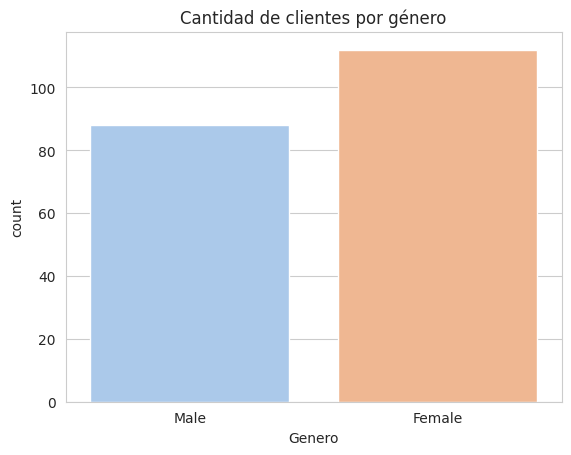

In [4]:
print(df[["Edad", "Ingreso", "Puntaje"]].describe().round(2))
print("\n", df["Genero"].value_counts())

sns.countplot(data=df, x="Genero", hue="Genero", palette="pastel", legend=False)
plt.title("Cantidad de clientes por género")
plt.show()

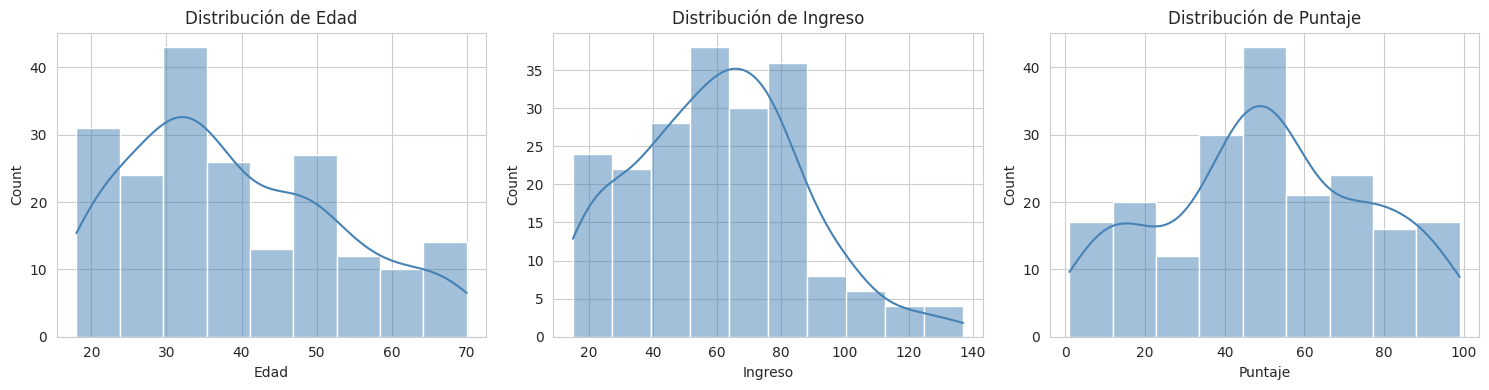

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col in zip(ejes, ["Edad", "Ingreso", "Puntaje"]):
    sns.histplot(df[col], kde=True, ax=eje, color="steelblue")
    eje.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

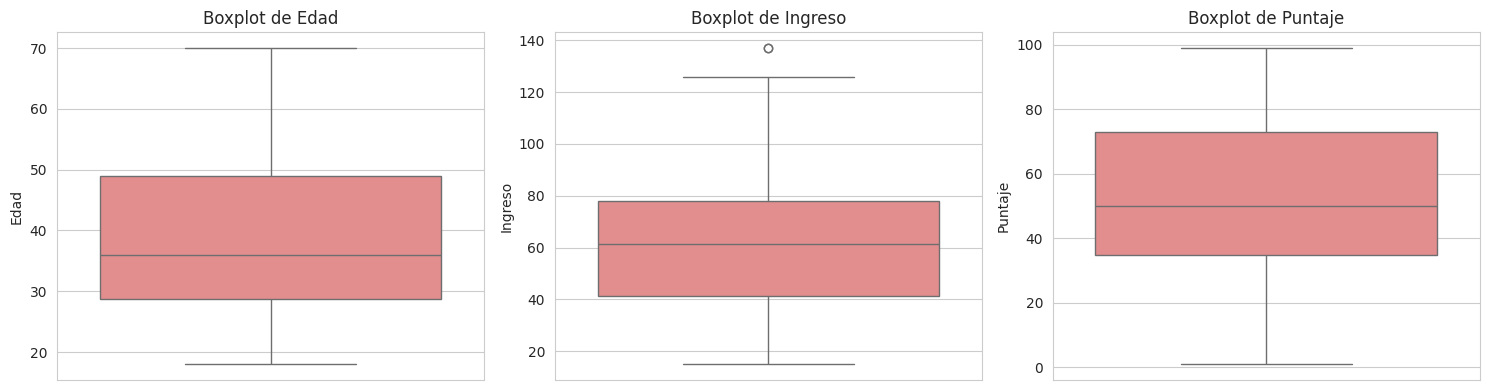

Edad: límites [-1.62, 79.38] -> 0 atípicos
Ingreso: límites [-13.25, 132.75] -> 2 atípicos
Puntaje: límites [-22.62, 130.38] -> 0 atípicos


In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col in zip(ejes, ["Edad", "Ingreso", "Puntaje"]):
    sns.boxplot(y=df[col], ax=eje, color="lightcoral")
    eje.set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

for col in ["Edad", "Ingreso", "Puntaje"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    atipicos = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: límites [{lim_inf:.2f}, {lim_sup:.2f}] -> {len(atipicos)} atípicos")

### Limpieza de datos

In [7]:
df_limpio = df.copy()
df_limpio = df_limpio.drop(columns=["CustomerID"])

antes = len(df_limpio)
df_limpio = df_limpio.dropna()
df_limpio = df_limpio.drop_duplicates()
print("Filas eliminadas por nulos o duplicados:", antes - len(df_limpio))

df_limpio["Genero"] = df_limpio["Genero"].str.strip().str.capitalize()
print("Categorías de Genero:", df_limpio["Genero"].unique())

print("Edad fuera de rango (18-100):", ((df_limpio["Edad"] < 18) | (df_limpio["Edad"] > 100)).sum())
print("Ingreso negativo o cero:", (df_limpio["Ingreso"] <= 0).sum())
print("Puntaje fuera de 1-100:", ((df_limpio["Puntaje"] < 1) | (df_limpio["Puntaje"] > 100)).sum())

print("\nTamaño final:", df_limpio.shape)
df_limpio.head()

Filas eliminadas por nulos o duplicados: 0
Categorías de Genero: ['Male' 'Female']
Edad fuera de rango (18-100): 0
Ingreso negativo o cero: 0
Puntaje fuera de 1-100: 0

Tamaño final: (200, 4)


,Genero,Edad,Ingreso,Puntaje
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


**Decisiones de limpieza:**
- Se eliminó `CustomerID` por ser un identificador sin significado para la segmentación.
- No se encontraron valores nulos ni registros duplicados.
- Se estandarizó el texto de la variable `Genero`.
- Todos los valores están dentro de rangos válidos.
- Los 2 valores atípicos de `Ingreso` (137 k$) **se conservan**, porque son datos reales y plausibles de clientes de altos ingresos, no errores de captura.

A partir de aquí se trabaja con `df_limpio`.

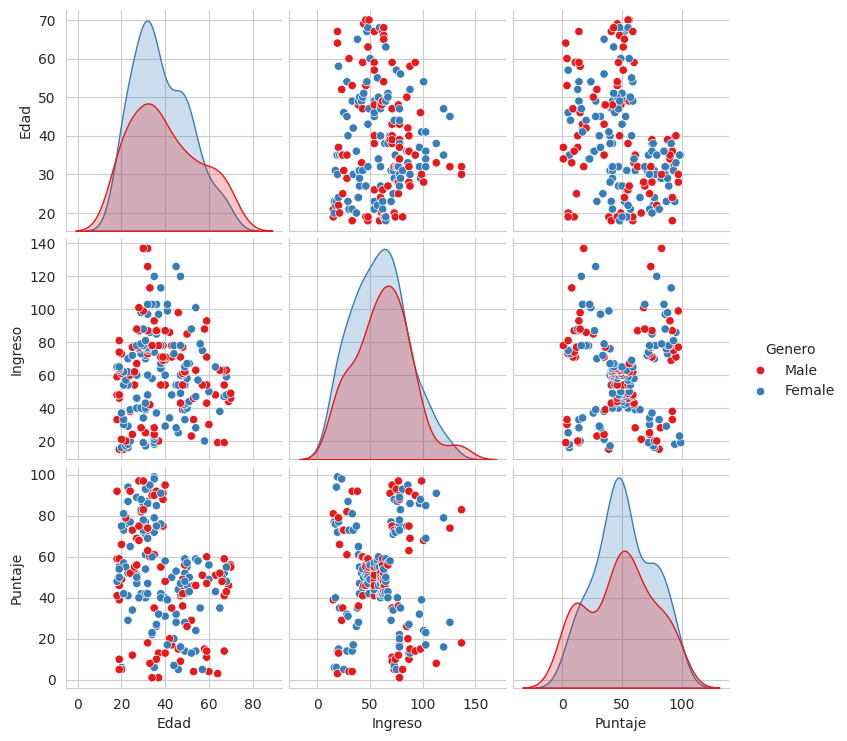

In [8]:
sns.pairplot(df_limpio, vars=["Edad", "Ingreso", "Puntaje"], hue="Genero", palette="Set1")
plt.show()

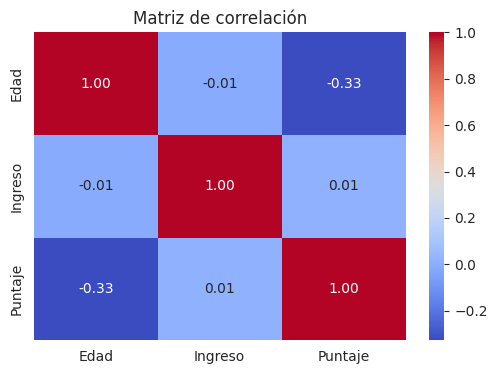

In [9]:
plt.figure(figsize=(6, 4))
sns.heatmap(df_limpio[["Edad", "Ingreso", "Puntaje"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

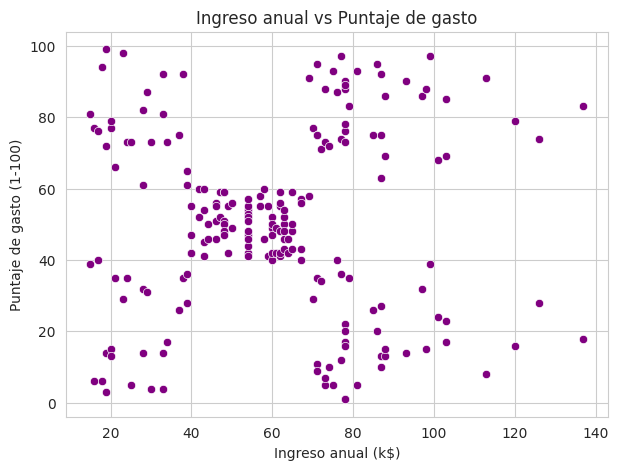

In [10]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_limpio, x="Ingreso", y="Puntaje", color="purple")
plt.title("Ingreso anual vs Puntaje de gasto")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto (1-100)")
plt.show()

### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**
Las más adecuadas son **Ingreso anual** y **Puntaje de gasto**, porque describen la capacidad de compra y el comportamiento de consumo, que es lo que interesa en marketing. En su diagrama de dispersión se observan agrupaciones bien definidas. `CustomerID` no aporta información (es un identificador) y `Genero` es categórica y no muestra diferencias marcadas. La `Edad` podría complementar, pero usar dos variables permite visualizar los clusters en un plano y facilita la interpretación.

**¿Se identifican valores atípicos?**
Con la regla del rango intercuartílico (IQR), solo **Ingreso** presenta **2 valores atípicos** (137 k$), que superan el límite superior de 132.75. Edad y Puntaje no presentan atípicos. Como se justificó en la limpieza, se **conservan** porque son valores reales y plausibles, y son muy pocos para distorsionar el modelo.

**¿Qué tipo de relaciones se observan entre las variables?**
- **Ingreso vs Puntaje:** correlación prácticamente nula (≈ 0.01), no hay relación lineal; pero el diagrama de dispersión muestra unos **cinco grupos**, es decir, la relación es por segmentos, ideal para clustering.
- **Edad vs Puntaje:** correlación negativa moderada (≈ -0.33): los clientes más jóvenes tienden a gastar más.
- **Edad vs Ingreso:** sin relación apreciable (≈ -0.01).